# Weight, height and WHO Z-scores as predictors of MUAC-defined malnutrition
## Children aged 6 to 60 months, Noakhali and Lakshmipur, Bangladesh: full reproducible analysis (revised submission)



## 1. Setup and data loading

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import logging
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
%matplotlib inline

rcParams['font.size'] = 11
rcParams['figure.dpi'] = 110

from scipy import stats
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_curve, auc, confusion_matrix, accuracy_score, balanced_accuracy_score,
    roc_auc_score, average_precision_score, matthews_corrcoef, f1_score, brier_score_loss
)
from statsmodels.stats.contingency_tables import mcnemar
import shap
from pygrowup import Calculator

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', None)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_BOOT = 2000
DATA_PATH = 'data/Malnutrition_Analysis_Dataset_FINAL.csv'

df = pd.read_csv(DATA_PATH)
df['sex_male'] = (df.SEX == 'male').astype(int)
df['area_noakhali'] = (df.Area == 'Noakhali').astype(int)

print(f"Loaded {len(df)} children, {df.shape[1]} columns")
print("Columns:", ", ".join(df.columns))
print("Missing values in any column:", int(df.isna().sum().sum()))

Loaded 465 children, 21 columns
Columns: ID, Area, SEX, BOD_raw, BOD_fixed, MONTH, WEIGHT, HEIGHT, MUAC, WAZ, HAZ, WHZ, stunted, wasted, underweight, overweight, undernutrition, muac_status, muac_malnourished, sex_male, area_noakhali
Missing values in any column: 0


## 2. Data checks


In [ ]:
logging.disable(logging.CRITICAL)
calc = Calculator(adjust_height_data=False, adjust_weight_scores=False, include_cdc=False)

def z_or_nan(fn, *args):
    try:
        return float(fn(*args))
    except Exception:
        return np.nan

recomputed = {'WAZ': [], 'HAZ': [], 'WHZ': []}
for _, r in df.iterrows():
    sex = 'M' if r.SEX == 'male' else 'F'
    age, w, h = Decimal(str(r.MONTH)), Decimal(str(r.WEIGHT)), Decimal(str(r.HEIGHT))
    recomputed['WAZ'].append(z_or_nan(calc.wfa, w, age, sex))
    recomputed['HAZ'].append(z_or_nan(calc.lhfa, h, age, sex))
    recomputed['WHZ'].append(z_or_nan(calc.wfl if r.MONTH < 24 else calc.wfh, w, age, sex, h))

zrows = []
for k, v in recomputed.items():
    v = np.array(v); s = df[k].values; ok = ~np.isnan(v)
    zrows.append([k, int(ok.sum()), f"{np.corrcoef(v[ok], s[ok])[0, 1]:.3f}",
                  f"{np.mean(np.abs(v[ok] - s[ok])):.2f}",
                  f"{np.mean(np.abs(v[ok] - s[ok]) <= 0.5) * 100:.1f}"])
pd.DataFrame(zrows, columns=["Index", "n", "Pearson r", "Mean absolute difference (SD)",
                             "% within ±0.5 SD"])

,Index,n,Pearson r,Mean absolute difference (SD),% within ±0.5 SD
0,WAZ,465,0.999,0.08,99.4
1,HAZ,465,0.999,0.10,98.5
2,WHZ,465,0.999,0.03,100.0


### 2b. Birth-year corrections

In [ ]:
n_fixed = int((df.BOD_raw != df.BOD_fixed).sum())
print(f"Records with a corrected birth year (BOD_raw != BOD_fixed): {n_fixed}")
print(f"Records excluded after measurement: 0 (analytic sample n = {len(df)})")

Records with a corrected birth year (BOD_raw != BOD_fixed): 25
Records excluded after measurement: 0 (analytic sample n = 465)


## 3. Table 1. Characteristics of 465 children aged 6 to 60 months

In [ ]:
def fmt_mean_sd(x):
    return f"{x.mean():.2f} ({x.std():.2f})"

table1 = pd.DataFrame({
    "Characteristic": [
        "Girls / boys", "Noakhali / Lakshmipur", "Age, months, mean (SD)",
        "Weight, kg, mean (SD)", "Height, cm, mean (SD)", "MUAC, cm, mean (SD)",
        "WAZ, mean (SD)", "HAZ, mean (SD)", "WHZ, mean (SD)",
    ],
    "Value": [
        f"{(df.SEX=='female').sum()} ({(df.SEX=='female').mean()*100:.1f}%) / "
        f"{(df.SEX=='male').sum()} ({(df.SEX=='male').mean()*100:.1f}%)",
        f"{(df.Area=='Noakhali').sum()} ({(df.Area=='Noakhali').mean()*100:.1f}%) / "
        f"{(df.Area=='Lakshmipur').sum()} ({(df.Area=='Lakshmipur').mean()*100:.1f}%)",
        fmt_mean_sd(df.MONTH), fmt_mean_sd(df.WEIGHT), fmt_mean_sd(df.HEIGHT),
        fmt_mean_sd(df.MUAC), fmt_mean_sd(df.WAZ), fmt_mean_sd(df.HAZ), fmt_mean_sd(df.WHZ),
    ]
})
table1

,Characteristic,Value
0,Girls / boys,244 (52.5%) / 221 (47.5%)
1,Noakhali / Lakshmipur,242 (52.0%) / 223 (48.0%)
2,"Age, months, mean (SD)",32.87 (16.15)
3,"Weight, kg, mean (SD)",11.21 (2.96)
4,"Height, cm, mean (SD)",83.72 (11.27)
5,"MUAC, cm, mean (SD)",14.25 (1.35)
6,"WAZ, mean (SD)",-1.42 (2.00)
7,"HAZ, mean (SD)",-2.01 (2.90)
8,"WHZ, mean (SD)",-0.29 (2.07)


## Table 2. Prevalence by WHO Z-score criteria (descriptive background epidemiology)

In [ ]:
def n_pct(mask):
    n = int(mask.sum())
    return n, 100 * n / len(df)

rows = []
for label, mask in [
    ("Stunting (HAZ < -2)", df.HAZ < -2),
    ("Severe stunting (HAZ < -3)", df.HAZ < -3),
    ("Underweight (WAZ < -2)", df.WAZ < -2),
    ("Severe underweight (WAZ < -3)", df.WAZ < -3),
    ("Wasting (WHZ < -2)", df.WHZ < -2),
    ("Severe wasting (WHZ < -3)", df.WHZ < -3),
    ("Overweight (WHZ > +2)", df.WHZ > 2),
    ("Any undernutrition (composite Z-score definition)", df.undernutrition == 1),
]:
    n, pct = n_pct(mask)
    rows.append([label, n, f"{pct:.1f}"])
table2 = pd.DataFrame(rows, columns=["Condition", "n", "%"])
table2

,Condition,n,%
0,Stunting (HAZ < -2),267,57.4
1,Severe stunting (HAZ < -3),219,47.1
2,Underweight (WAZ < -2),199,42.8
3,Severe underweight (WAZ < -3),119,25.6
4,Wasting (WHZ < -2),106,22.8
5,Severe wasting (WHZ < -3),47,10.1
6,Overweight (WHZ > +2),67,14.4
7,Any undernutrition (composite Z-score definition),325,69.9


## 4. Demonstrating the leakage problem



In [ ]:
def screen_metrics(pred, truth):
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
    acc = (tp + tn) / (tp + tn + fp + fn)
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    ppv = tp / (tp + fp) if (tp + fp) else np.nan
    npv = tn / (tn + fn) if (tn + fn) else np.nan
    return acc, (sens + spec) / 2, sens, spec, ppv, npv

rows = []
truth = df.undernutrition.values
for cutoff in [11.5, 12.5, 13.5]:
    pred = (df.MUAC.values < cutoff).astype(int)
    acc, bacc, sens, spec, ppv, npv = screen_metrics(pred, truth)
    rows.append([f"MUAC < {cutoff} cm", f"{acc*100:.1f}", f"{bacc*100:.1f}", f"{sens*100:.1f}",
                 f"{spec*100:.1f}", f"{ppv*100:.1f}", f"{npv*100:.1f}"])
table3 = pd.DataFrame(rows, columns=["Cut-off", "Accuracy", "Balanced acc.", "Sensitivity",
                                      "Specificity", "PPV", "NPV"])
table3

,Cut-off,Accuracy,Balanced acc.,Sensitivity,Specificity,PPV,NPV
0,MUAC < 11.5 cm,30.3,49.7,0.9,98.6,60.0,30.0
1,MUAC < 12.5 cm,33.3,50.1,8.0,92.1,70.3,30.1
2,MUAC < 13.5 cm,41.9,52.8,25.5,80.0,74.8,31.6


### Table 4. Illustration: cross-validated performance predicting the composite Z-score outcome



In [ ]:
def make_lr():
    return Pipeline([('s', StandardScaler()),
                     ('m', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))])

def make_dt():
    return DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE)

def make_svm():
    return Pipeline([('s', StandardScaler()),
                     ('m', SVC(probability=True, class_weight='balanced', random_state=RANDOM_STATE))])

def make_mlp():
    return Pipeline([('s', StandardScaler()),
                     ('m', MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=3000, random_state=RANDOM_STATE))])

def make_gb():
    return GradientBoostingClassifier(random_state=RANDOM_STATE)

def make_rf_old():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', random_state=RANDOM_STATE)

def make_stack_old():
    return StackingClassifier(
        estimators=[('lr', make_lr()), ('dt', make_dt()),
                    ('rf', RandomForestClassifier(n_estimators=150, min_samples_leaf=5, class_weight='balanced', random_state=RANDOM_STATE))],
        final_estimator=LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
        cv=5, n_jobs=-1)

def make_rf_new():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_depth=6, class_weight='balanced', random_state=RANDOM_STATE)

def make_stack_new():
    return StackingClassifier(
        estimators=[('lr', make_lr()), ('dt', make_dt()), ('rf', make_rf_new())],
        final_estimator=LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
        cv=5, n_jobs=-1)

MODELS_OLD = {'Logistic Regression': make_lr, 'Decision Tree': make_dt, 'SVM (RBF)': make_svm,
              'MLP': make_mlp, 'Random Forest': make_rf_old, 'Gradient Boosting': make_gb,
              'Stacking Ensemble': make_stack_old}
MODELS_NEW = {'Logistic Regression': make_lr, 'Decision Tree': make_dt, 'SVM (RBF)': make_svm,
              'MLP': make_mlp, 'Random Forest': make_rf_new, 'Gradient Boosting': make_gb,
              'Stacking Ensemble': make_stack_new}
MODEL_ORDER = list(MODELS_NEW.keys())

def summarise_folds(fold_rows):
    f = pd.DataFrame(fold_rows); out = {}
    for k in f.columns:
        lo, hi = np.percentile(f[k], [2.5, 97.5])
        out[k] = f[k].mean(); out[k + '_lo'] = lo; out[k + '_hi'] = hi
    return out

def cv_metrics_std(model_proto, X, y, n_splits=5, n_repeats=4):
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=RANDOM_STATE)
    fold_rows = []
    for tr, te in cv.split(X, y):
        m = clone(model_proto()).fit(X[tr], y[tr])
        pr = m.predict_proba(X[te])[:, 1]
        pred = (pr >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y[te], pred, labels=[0, 1]).ravel()
        fold_rows.append(dict(
            acc=accuracy_score(y[te], pred), bacc=balanced_accuracy_score(y[te], pred),
            sens=tp/(tp+fn) if (tp+fn) else np.nan, spec=tn/(tn+fp) if (tn+fp) else np.nan,
            auc=roc_auc_score(y[te], pr)))
    return summarise_folds(fold_rows)

OLD_SETS = {
    'A': ['MUAC', 'MONTH', 'sex_male', 'area_noakhali'],
    'B': ['MUAC', 'MONTH', 'sex_male', 'area_noakhali', 'WEIGHT', 'HEIGHT'],
    'C': ['MUAC', 'MONTH', 'sex_male', 'area_noakhali', 'WEIGHT', 'HEIGHT', 'WAZ', 'HAZ', 'WHZ'],
}
y_old = df.undernutrition.values
old_grid_rows = []
for sname, cols in OLD_SETS.items():
    X = df[cols].values
    for mname, proto in MODELS_OLD.items():
        r = cv_metrics_std(proto, X, y_old); r['features'] = sname; r['model'] = mname
        old_grid_rows.append(r)
old_grid = pd.DataFrame(old_grid_rows)

def best_row(grid, sname, by='acc'):
    sub = grid[grid.features == sname]
    return sub.loc[sub[by].idxmax()]

rows = []
label_map = {'A': 'A: demographics', 'B': 'B: + weight, height',
             'C': 'B + WAZ/HAZ/WHZ (composite Z-score outcome, not used further)'}
for sname in ['A', 'B', 'C']:
    b = best_row(old_grid, sname, by='acc')
    rows.append([label_map[sname], b['model'],
                 f"{b.acc*100:.1f} ({b.acc_lo*100:.1f} to {b.acc_hi*100:.1f})",
                 f"{b.bacc*100:.1f}", f"{b.sens*100:.1f}", f"{b.spec*100:.1f}",
                 f"{b.auc:.3f} ({b.auc_lo:.3f} to {b.auc_hi:.3f})"])
table4 = pd.DataFrame(rows, columns=["Configuration", "Best model", "Accuracy (95% PI)",
                                      "Balanced acc.", "Sensitivity", "Specificity", "AUC (95% PI)"])
table4

,Configuration,Best model,Accuracy (95% PI),Balanced acc.,Sensitivity,Specificity,AUC (95% PI)
0,A: demographics,MLP,72.3 (65.5 to 77.4),58.4,93.3,23.6,0.674 (0.555 to 0.787)
1,"B: + weight, height",MLP,92.7 (86.5 to 97.3),91.1,95.2,87.0,0.982 (0.964 to 0.996)
2,"B + WAZ/HAZ/WHZ (composite Z-score outcome, not used further)",Gradient Boosting,99.5 (97.8 to 100.0),99.4,99.5,99.3,0.994 (0.978 to 1.000)


The composite outcome is `undernutrition = 1` **if and only if** `WAZ < -2 or HAZ < -2 or WHZ < -2`:

In [ ]:
implied = ((df.WAZ < -2) | (df.HAZ < -2) | (df.WHZ < -2)).astype(int)
print(f"Agreement between 'any Z-score < -2' and the stored 'undernutrition' label: "
      f"{(implied == df.undernutrition).sum()}/{len(df)} = {(implied == df.undernutrition).mean()*100:.1f}%")

Agreement between 'any Z-score < -2' and the stored 'undernutrition' label: 465/465 = 100.0%


## 5. Table 5. MUAC-defined nutritional status: an independent outcome



In [ ]:
n_normal = (df.muac_status == 'Normal').sum()
n_mod = (df.muac_status == 'Moderate malnutrition').sum()
n_sev = (df.muac_status == 'Severe malnutrition').sum()
n_mal = df.muac_malnourished.sum()
assert n_mod + n_sev == n_mal
table5 = pd.DataFrame({
    "Status": ["Normal (MUAC >= 12.5 cm)", "Moderate malnutrition (11.5 to <12.5 cm)",
               "Severe malnutrition (<11.5 cm)", "Malnourished, combined (primary outcome)"],
    "n": [n_normal, n_mod, n_sev, n_mal],
    "%": [f"{n_normal/len(df)*100:.1f}", f"{n_mod/len(df)*100:.1f}",
          f"{n_sev/len(df)*100:.1f}", f"{n_mal/len(df)*100:.1f}"]
})
table5

,Status,n,%
0,Normal (MUAC >= 12.5 cm),428,92.0
1,Moderate malnutrition (11.5 to <12.5 cm),32,6.9
2,Severe malnutrition (<11.5 cm),5,1.1
3,"Malnourished, combined (primary outcome)",37,8.0


In [ ]:
print("Malnutrition by district (n malnourished / n, %):")
print(df.groupby('Area').muac_malnourished.agg(['sum', 'count', lambda s: round(s.mean()*100, 1)])
        .rename(columns={'<lambda_0>': '%'}))
print("\nMalnutrition by sex:")
print(df.groupby('SEX').muac_malnourished.agg(['sum', 'count', lambda s: round(s.mean()*100, 1)])
        .rename(columns={'<lambda_0>': '%'}))
print("\nCorrelation of MUAC with candidate predictors:")
for col in ['WAZ', 'HAZ', 'WHZ', 'WEIGHT', 'HEIGHT']:
    print(f"  MUAC vs {col}: r = {df.MUAC.corr(df[col]):.3f}")

Malnutrition by district (n malnourished / n, %):
            sum  count     %
Area                        
Lakshmipur   11    223   4.9
Noakhali     26    242  10.7

Malnutrition by sex:
        sum  count    %
SEX                    
female   18    244  7.4
male     19    221  8.6

Correlation of MUAC with candidate predictors:
  MUAC vs WAZ: r = 0.151
  MUAC vs HAZ: r = 0.070
  MUAC vs WHZ: r = 0.126
  MUAC vs WEIGHT: r = 0.390
  MUAC vs HEIGHT: r = 0.349


### Events per candidate predictor (Section 2.6)

In [ ]:
NEW_SETS = {
    'A': ['MONTH', 'sex_male', 'area_noakhali'],
    'B': ['MONTH', 'sex_male', 'area_noakhali', 'WEIGHT', 'HEIGHT'],
    'C': ['MONTH', 'sex_male', 'area_noakhali', 'WEIGHT', 'HEIGHT', 'WAZ', 'HAZ', 'WHZ'],
}
y_new = df.muac_malnourished.values
for s, cols in NEW_SETS.items():
    print(f"Set {s}: {y_new.sum()} events / {len(cols)} candidate predictors = {y_new.sum()/len(cols):.1f} events per predictor")

Set A: 37 events / 3 candidate predictors = 12.3 events per predictor
Set B: 37 events / 5 candidate predictors = 7.4 events per predictor
Set C: 37 events / 8 candidate predictors = 4.6 events per predictor


## 6. Predicting MUAC-defined malnutrition (the corrected, recommended analysis)



In [ ]:
def youden_threshold(y_true, proba):
    fpr, tpr, thr = roc_curve(y_true, proba)
    return thr[np.argmax(tpr - fpr)]

def inner_threshold(model_proto, X_train, y_train):
    """Youden-optimal threshold chosen from out-of-fold predictions of an inner
    5-fold cross-validation within the training data, so that the threshold is
    selected on predictions for children the model was not fitted to."""
    p_inner = cross_val_predict(clone(model_proto()), X_train, y_train,
                                cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                                method='predict_proba')[:, 1]
    return youden_threshold(y_train, p_inner)

def metrics_at_threshold(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(
        acc=accuracy_score(y_true, pred), bacc=balanced_accuracy_score(y_true, pred),
        sens=tp/(tp+fn) if (tp+fn) else np.nan, spec=tn/(tn+fp) if (tn+fp) else np.nan,
        ppv=tp/(tp+fp) if (tp+fp) else np.nan, npv=tn/(tn+fn) if (tn+fn) else np.nan,
        f1=f1_score(y_true, pred, zero_division=0), mcc=matthews_corrcoef(y_true, pred),
        auc=roc_auc_score(y_true, proba), ap=average_precision_score(y_true, proba),
        brier=brier_score_loss(y_true, proba))

def cv_metrics_youden(model_proto, X, y, n_splits=5, n_repeats=4):
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=RANDOM_STATE)
    fold_rows = []
    for tr, te in cv.split(X, y):
        m = clone(model_proto()).fit(X[tr], y[tr])
        thr = inner_threshold(model_proto, X[tr], y[tr])
        fold_rows.append(metrics_at_threshold(y[te], m.predict_proba(X[te])[:, 1], thr))
    return summarise_folds(fold_rows)

print(f"Corrected outcome prevalence: {y_new.sum()}/{len(y_new)} ({y_new.mean()*100:.1f}%)")
new_grid_rows = []
for sname, cols in NEW_SETS.items():
    X = df[cols].values
    for mname, proto in MODELS_NEW.items():
        r = cv_metrics_youden(proto, X, y_new); r['features'] = sname; r['model'] = mname
        new_grid_rows.append(r)
new_grid = pd.DataFrame(new_grid_rows)
print(f"Cross-validation complete: {len(new_grid)} model x predictor-set combinations.")

Corrected outcome prevalence: 37/465 (8.0%)


Cross-validation complete: 21 model x predictor-set combinations.


### Table 6. Cross-validated performance predicting MUAC-defined malnutrition (best model per predictor set)

In [ ]:
rows = []
label_map6 = {'A': 'A: demographics', 'B': 'B: + weight, height', 'C': 'C: + WAZ/HAZ/WHZ (recommended)'}
for sname in ['A', 'B', 'C']:
    b = best_row(new_grid, sname, by='auc')
    rows.append([label_map6[sname], b['model'],
                 f"{b.acc*100:.1f} ({b.acc_lo*100:.1f} to {b.acc_hi*100:.1f})",
                 f"{b.bacc*100:.1f}", f"{b.sens*100:.1f}", f"{b.spec*100:.1f}",
                 f"{b.auc:.3f} ({b.auc_lo:.3f} to {b.auc_hi:.3f})"])
table6 = pd.DataFrame(rows, columns=["Predictor set", "Best model", "Accuracy (95% PI)",
                                      "Balanced acc.", "Sensitivity", "Specificity", "AUC (95% PI)"])
table6

,Predictor set,Best model,Accuracy (95% PI),Balanced acc.,Sensitivity,Specificity,AUC (95% PI)
0,A: demographics,Logistic Regression,71.7 (58.6 to 86.2),65.7,58.6,72.8,0.701 (0.579 to 0.801)
1,"B: + weight, height",Logistic Regression,75.6 (58.0 to 90.9),65.6,53.8,77.4,0.711 (0.595 to 0.814)
2,C: + WAZ/HAZ/WHZ (recommended),Logistic Regression,74.4 (57.0 to 88.7),65.2,54.5,76.0,0.706 (0.583 to 0.811)


### Table S1 (Supporting Information). Full cross-validated model grid, corrected outcome

In [ ]:
s1_rows = []
for sname in ['A', 'B', 'C']:
    for mname in MODEL_ORDER:
        r = new_grid[(new_grid.features == sname) & (new_grid.model == mname)].iloc[0]
        s1_rows.append([sname, mname, f"{r.acc*100:.1f} ({r.acc_lo*100:.1f} to {r.acc_hi*100:.1f})",
                        f"{r.bacc*100:.1f}", f"{r.sens*100:.1f}", f"{r.spec*100:.1f}",
                        f"{r.ppv*100:.1f}", f"{r.npv*100:.1f}", f"{r.f1*100:.1f}",
                        f"{r.mcc:.3f}", f"{r.auc:.3f}", f"{r.ap:.3f}", f"{r.brier:.3f}"])
table_s1 = pd.DataFrame(s1_rows, columns=["Set", "Model", "Accuracy (95% PI)", "Bal. acc.",
                                           "Sens.", "Spec.", "PPV", "NPV", "F1", "MCC", "AUC",
                                           "PR-AUC", "Brier"])
table_s1

,Set,Model,Accuracy (95% PI),Bal. acc.,Sens.,Spec.,PPV,NPV,F1,MCC,AUC,PR-AUC,Brier
0,A,Logistic Regression,71.7 (58.6 to 86.2),65.7,58.6,72.8,16.5,95.5,24.9,0.191,0.701,0.292,0.215
1,A,Decision Tree,80.2 (69.8 to 89.8),63.1,42.9,83.3,20.1,94.4,26.3,0.192,0.606,0.190,0.194
2,A,SVM (RBF),73.4 (64.0 to 81.8),65.1,55.3,75.0,16.0,95.2,24.6,0.184,0.663,0.259,0.071
3,A,MLP,76.1 (59.0 to 86.1),65.2,52.4,78.1,17.9,95.1,26.3,0.198,0.681,0.281,0.070
4,A,Random Forest,66.3 (47.2 to 86.7),60.7,54.0,67.4,13.8,94.6,20.9,0.131,0.699,0.308,0.100
5,A,Gradient Boosting,74.2 (49.8 to 84.9),59.0,40.9,77.0,14.1,93.8,20.2,0.118,0.648,0.224,0.087
6,A,Stacking Ensemble,67.6 (44.4 to 83.5),61.4,54.0,68.7,13.4,94.7,20.9,0.135,0.676,0.320,0.214
7,B,Logistic Regression,75.6 (58.0 to 90.9),65.6,53.8,77.4,21.4,95.2,27.3,0.218,0.711,0.289,0.207
8,B,Decision Tree,72.4 (43.9 to 88.8),58.8,42.8,74.9,15.3,93.8,20.7,0.123,0.582,0.158,0.206
9,B,SVM (RBF),76.2 (62.8 to 87.2),63.9,49.3,78.6,17.6,94.7,25.3,0.184,0.644,0.282,0.070


### Figure 1. Cross-validated AUC for every model under Set A, Set B and Set C

Bars: mean across 20 folds. Error bars: 95% percentile interval of fold-level AUC.

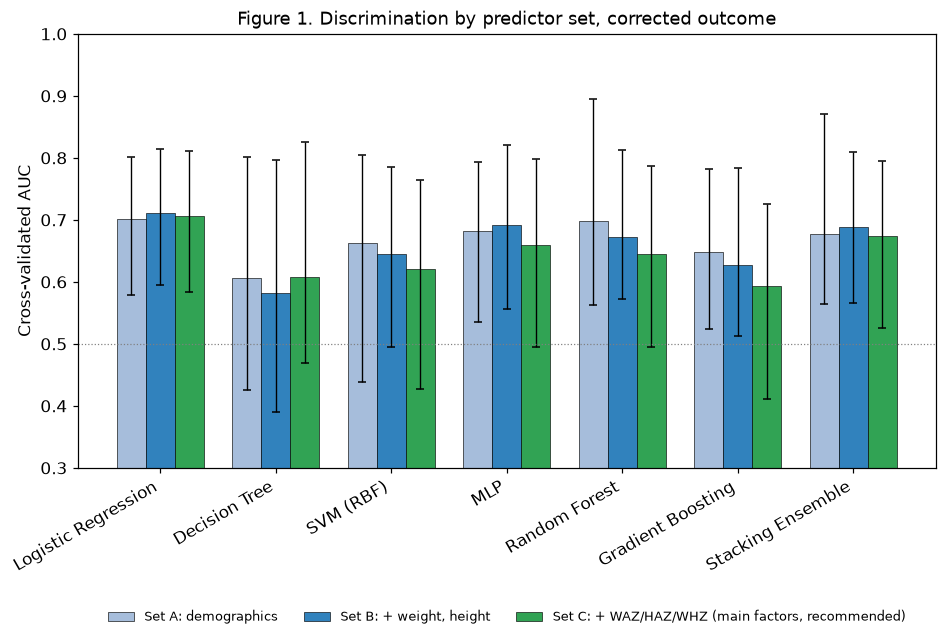

In [ ]:
colors = {'A': '#a6bddb', 'B': '#3182bd', 'C': '#31a354'}
set_labels = {'A': 'Set A: demographics', 'B': 'Set B: + weight, height',
              'C': 'Set C: + WAZ/HAZ/WHZ (main factors, recommended)'}
fig, ax = plt.subplots(figsize=(9, 6.2))
w = 0.25; xpos = np.arange(len(MODEL_ORDER))
for i, s in enumerate(['A', 'B', 'C']):
    rr = [new_grid[(new_grid.features == s) & (new_grid.model == m)].iloc[0] for m in MODEL_ORDER]
    a = np.array([q.auc for q in rr]); lo = np.array([q.auc_lo for q in rr]); hi = np.array([q.auc_hi for q in rr])
    ax.bar(xpos + (i - 1) * w, a, w, yerr=[a - lo, hi - a], capsize=2.5,
           error_kw=dict(elinewidth=0.9, ecolor='black'), label=set_labels[s], color=colors[s],
           edgecolor='black', linewidth=0.4)
ax.set_xticks(xpos); ax.set_xticklabels(MODEL_ORDER, rotation=30, ha='right')
ax.set_ylabel('Cross-validated AUC'); ax.set_ylim(0.3, 1.0)
ax.axhline(0.5, color='grey', lw=0.8, ls=':')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.30), fontsize=8.5, frameon=False, ncol=3)
ax.set_title('Figure 1. Discrimination by predictor set, corrected outcome', fontsize=12)
plt.tight_layout(); plt.show()

## 7. Held-out evaluation and model comparison

All models refitted on a stratified 80/20 split (training n = 372, test n = 93).

In [ ]:
idx = np.arange(len(df))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, stratify=y_new, random_state=RANDOM_STATE)
print(f"Training set: n={len(tr_idx)} (malnourished {y_new[tr_idx].sum()})")
print(f"Held-out test set: n={len(te_idx)} (malnourished {y_new[te_idx].sum()}, normal {(1-y_new[te_idx]).sum()})")

fitted = {}
for sname, cols in NEW_SETS.items():
    X = df[cols].values
    Xtr, Xte = X[tr_idx], X[te_idx]
    ytr, yte = y_new[tr_idx], y_new[te_idx]
    for mname, proto in MODELS_NEW.items():
        m = proto().fit(Xtr, ytr)
        thr = inner_threshold(proto, Xtr, ytr)
        pr_te = m.predict_proba(Xte)[:, 1]
        fitted[(sname, mname)] = dict(model=m, Xte=Xte, yte=yte, pr=pr_te,
                                      pred=(pr_te >= thr).astype(int), thr=thr)

f = fitted[('C', 'Logistic Regression')]
print(f"\nLogistic regression, Set C, held-out: acc={accuracy_score(f['yte'], f['pred'])*100:.1f}% "
      f"bacc={balanced_accuracy_score(f['yte'], f['pred'])*100:.1f}% "
      f"AUC={roc_auc_score(f['yte'], f['pr']):.3f} "
      f"(identified {int((f['pred'][f['yte']==1]==1).sum())}/{int(f['yte'].sum())} malnourished)")

Training set: n=372 (malnourished 30)
Held-out test set: n=93 (malnourished 7, normal 86)



Logistic regression, Set C, held-out: acc=87.1% bacc=66.8% AUC=0.723 (identified 3/7 malnourished)


### Figure 2. ROC curves for the best model under Set A, Set B and Set C

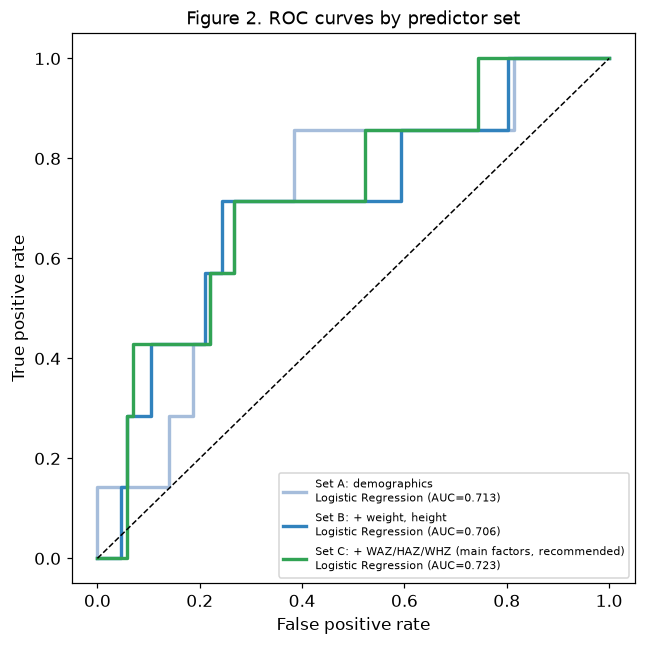

In [ ]:
best_by_set = {s: new_grid[new_grid.features == s].loc[new_grid[new_grid.features == s].auc.idxmax(), 'model']
               for s in ['A', 'B', 'C']}
fig, ax = plt.subplots(figsize=(6, 6))
for s in ['A', 'B', 'C']:
    mname = best_by_set[s]; fi = fitted[(s, mname)]
    fpr, tpr, _ = roc_curve(fi['yte'], fi['pr'])
    ax.plot(fpr, tpr, color=colors[s], lw=2.2, label=f"{set_labels[s]}\n{mname} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('Figure 2. ROC curves by predictor set', fontsize=12)
ax.legend(loc='lower right', fontsize=7.5)
plt.tight_layout(); plt.show()

### Figure 3. Confusion matrices for all seven classifiers under Set C

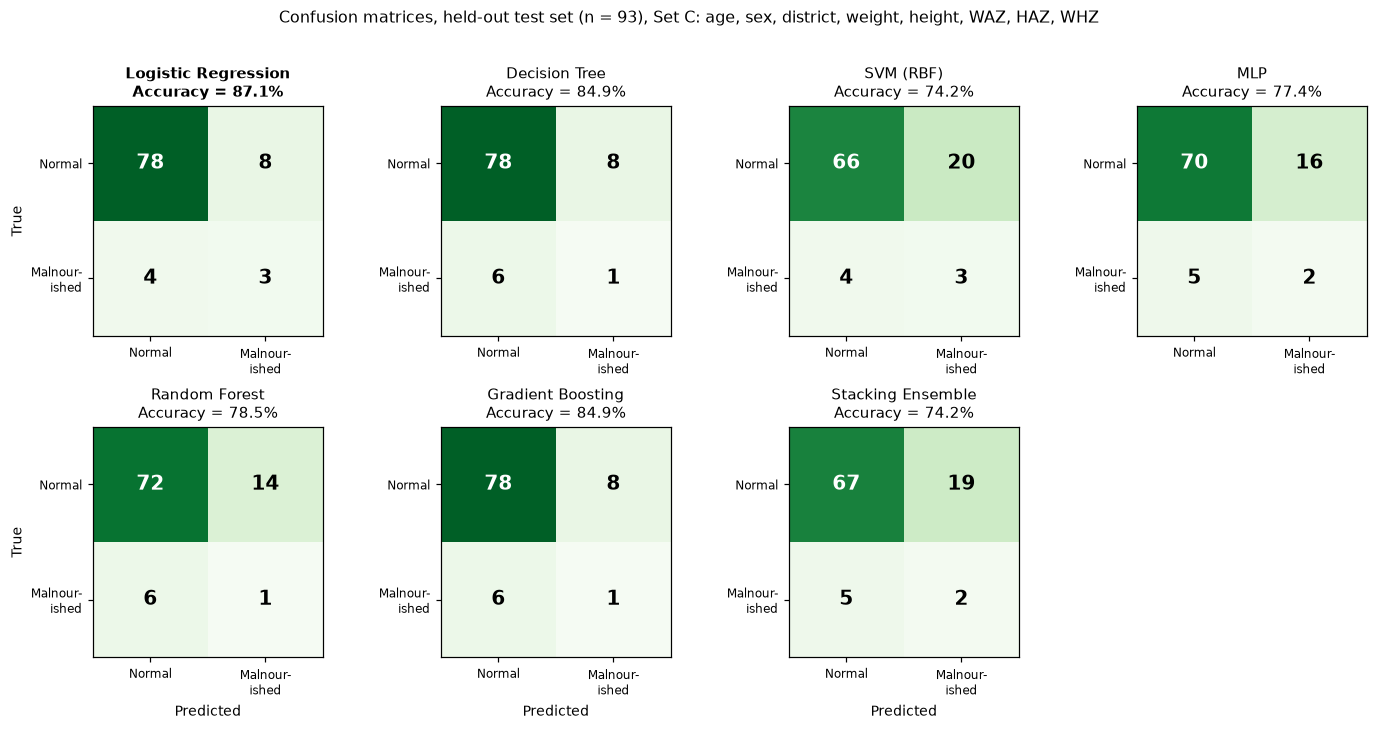

,Model,TN,FP,FN,TP,Accuracy
0,Logistic Regression,78,8,4,3,87.1%
1,Decision Tree,78,8,6,1,84.9%
2,SVM (RBF),66,20,4,3,74.2%
3,MLP,70,16,5,2,77.4%
4,Random Forest,72,14,6,1,78.5%
5,Gradient Boosting,78,8,6,1,84.9%
6,Stacking Ensemble,67,19,5,2,74.2%


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5)); axes = axes.flatten()
cm_summary = []
for i, mname in enumerate(MODEL_ORDER):
    ax = axes[i]; fi = fitted[('C', mname)]
    cm = confusion_matrix(fi['yte'], fi['pred']); acc = accuracy_score(fi['yte'], fi['pred'])
    tn, fp, fn, tp = cm.ravel(); cm_summary.append([mname, tn, fp, fn, tp, f"{acc*100:.1f}%"])
    ax.imshow(cm, cmap='Greens', vmin=0, vmax=85)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha='center', va='center',
                    color='white' if cm[r, c] > 42 else 'black', fontsize=13, fontweight='bold')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Normal', 'Malnour-\nished'], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Normal', 'Malnour-\nished'], fontsize=8)
    ax.set_title(f"{mname}\nAccuracy = {acc*100:.1f}%", fontsize=10,
                 fontweight='bold' if mname == 'Logistic Regression' else 'normal')
    if i % 4 == 0: ax.set_ylabel('True', fontsize=9)
    if i >= 4: ax.set_xlabel('Predicted', fontsize=9)
axes[7].axis('off')
fig.suptitle('Confusion matrices, held-out test set (n = 93), Set C: age, sex, district, weight, height, WAZ, HAZ, WHZ',
             fontsize=10.5, y=1.01)
plt.tight_layout(); plt.show()
pd.DataFrame(cm_summary, columns=["Model", "TN", "FP", "FN", "TP", "Accuracy"])

### Table 7. Exact McNemar tests, logistic regression versus each comparator (Set C, held-out, n = 93)



In [ ]:
def clopper_pearson_or(b, c, alpha=0.05):
    n = b + c
    lo = 0.0 if b == 0 else stats.beta.ppf(alpha / 2, b, n - b + 1)
    hi = 1.0 if b == n else stats.beta.ppf(1 - alpha / 2, b + 1, n - b)
    to_or = lambda p: p / (1 - p) if p < 1 else np.inf
    return (b / c if c else np.inf), to_or(lo), to_or(hi)

def fmt_p(p):
    if p < 0.001: return "<.001"
    if p > 0.99:  return ">.99"
    if p < 0.01:  return f"{p:.3f}".lstrip('0')
    return f"{p:.2f}".lstrip('0')

def fmt_or(x):
    if x == 0: return "0"
    return "<0.01" if x < 0.005 else f"{x:.2f}"

rows = []
lr_pred = fitted[('C', 'Logistic Regression')]['pred']; yte_c = fitted[('C', 'Logistic Regression')]['yte']
for mname in MODEL_ORDER:
    if mname == 'Logistic Regression':
        continue
    other_pred = fitted[('C', mname)]['pred']
    t = pd.crosstab(lr_pred == yte_c, other_pred == yte_c).values
    b, c = int(t[0, 1]), int(t[1, 0])
    p = mcnemar(t, exact=True).pvalue
    o, lo, hi = clopper_pearson_or(b, c)
    rows.append([f"Logistic regression vs {mname}", f"{b}, {c}",
                 f"{fmt_or(o)} ({fmt_or(lo)} to {fmt_or(hi)})", fmt_p(p), round(p, 4)])
table7 = pd.DataFrame(rows, columns=["Comparison", "Discordant (b, c)", "OR (95% CI)", "P", "P (unrounded)"])
print(f"Bonferroni-adjusted threshold for six comparisons: 0.05/6 = {0.05/6:.4f}")
table7

Bonferroni-adjusted threshold for six comparisons: 0.05/6 = 0.0083


,Comparison,"Discordant (b, c)",OR (95% CI),P,P (unrounded)
0,Logistic regression vs Decision Tree,"6, 8",0.75 (0.21 to 2.46),.79,0.7905
1,Logistic regression vs SVM (RBF),"1, 13",0.08 (<0.01 to 0.51),.002,0.0018
2,Logistic regression vs MLP,"1, 10",0.10 (<0.01 to 0.70),.01,0.0117
3,Logistic regression vs Random Forest,"1, 9",0.11 (<0.01 to 0.80),.02,0.0215
4,Logistic regression vs Gradient Boosting,"7, 9",0.78 (0.25 to 2.35),.80,0.8036
5,Logistic regression vs Stacking Ensemble,"0, 12",0 (0 to 0.36),<.001,0.0005


## 8. Interpretability: the WHO Z-scores as leading predictors

### Figure 4. Standardized logistic-regression coefficients, Set C



Standardized coefficients (Set C), 95% bootstrap interval:
  HAZ                    +1.081  (-0.231 to +2.094)
  WAZ                    -0.962  (-1.845 to +0.041)
  Height                 -0.860  (-1.976 to +0.406)
  District (Noakhali)    +0.387  (-0.058 to +0.996)
  WHZ                    +0.211  (-0.635 to +0.978)
  Sex (male)             +0.210  (-0.245 to +0.671)
  Age (months)           +0.074  (-1.438 to +1.230)
  Weight                 +0.031  (-1.692 to +1.317)


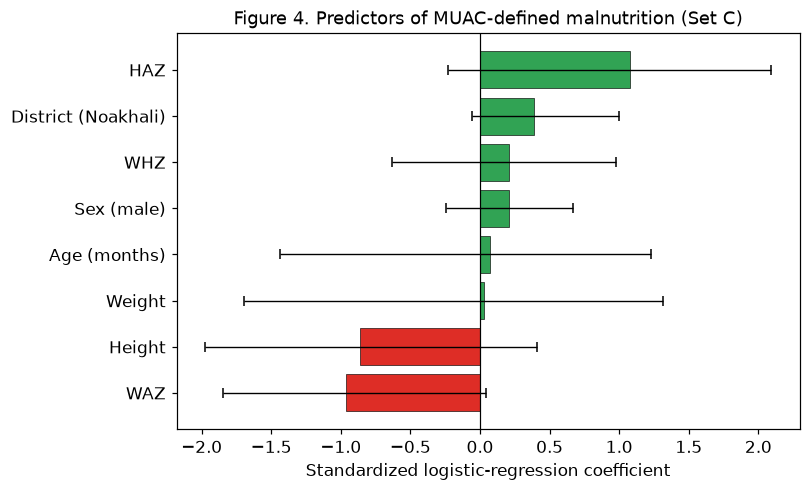

In [ ]:
labels_full = ['Age (months)', 'Sex (male)', 'District (Noakhali)', 'Weight', 'Height', 'WAZ', 'HAZ', 'WHZ']
cols_full = NEW_SETS['C']
Xtr_c, Xte_c = df[cols_full].values[tr_idx], df[cols_full].values[te_idx]
ytr_c, yte_c2 = y_new[tr_idx], y_new[te_idx]

lr_pipe = make_lr().fit(Xtr_c, ytr_c)
coefs = lr_pipe.named_steps['m'].coef_[0]

rng = np.random.default_rng(RANDOM_STATE); boot_std = []
while len(boot_std) < N_BOOT:
    i = rng.integers(0, len(ytr_c), len(ytr_c))
    if ytr_c[i].sum() < 2:
        continue
    boot_std.append(make_lr().fit(Xtr_c[i], ytr_c[i]).named_steps['m'].coef_[0])
boot_std = np.array(boot_std)
c_lo, c_hi = np.percentile(boot_std, [2.5, 97.5], axis=0)

print("Standardized coefficients (Set C), 95% bootstrap interval:")
for i in np.argsort(-np.abs(coefs)):
    print(f"  {labels_full[i]:22s} {coefs[i]:+.3f}  ({c_lo[i]:+.3f} to {c_hi[i]:+.3f})")

o = np.argsort(coefs)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(np.array(labels_full)[o], coefs[o], xerr=[coefs[o] - c_lo[o], c_hi[o] - coefs[o]], capsize=3,
        error_kw=dict(elinewidth=0.9, ecolor='black'),
        color=['#de2d26' if c < 0 else '#31a354' for c in coefs[o]], edgecolor='black', linewidth=0.4)
ax.axvline(0, color='black', lw=0.8); ax.set_xlabel('Standardized logistic-regression coefficient')
ax.set_title('Figure 4. Predictors of MUAC-defined malnutrition (Set C)', fontsize=12)
plt.tight_layout(); plt.show()

### Permutation importance (Set C, logistic regression, held-out test set)

Mean decrease in AUC over 50 permutations of each predictor.

In [ ]:
pi = permutation_importance(lr_pipe, Xte_c, yte_c2, n_repeats=50, random_state=RANDOM_STATE, scoring='roc_auc')
print("Permutation importance (drop in held-out AUC when each predictor is shuffled):")
for i in np.argsort(-pi.importances_mean):
    print(f"  {labels_full[i]:22s} {pi.importances_mean[i]:+.4f} +/- {pi.importances_std[i]:.4f}")

Permutation importance (drop in held-out AUC when each predictor is shuffled):
  Height                 +0.2601 +/- 0.0921
  WAZ                    +0.0801 +/- 0.0682
  HAZ                    +0.0766 +/- 0.0488
  WHZ                    +0.0283 +/- 0.0222
  District (Noakhali)    +0.0042 +/- 0.0469
  Weight                 -0.0016 +/- 0.0035
  Age (months)           -0.0057 +/- 0.0087
  Sex (male)             -0.0080 +/- 0.0211


### Figure 5. Mean |SHAP value|, Set C (random forest, held-out test set)



SHAP mean |value| (Set C random forest), 95% bootstrap interval:
  Age (months)           0.1046  (0.0945 to 0.1143)
  Weight                 0.0621  (0.0581 to 0.0664)
  WHZ                    0.0551  (0.0470 to 0.0640)
  Height                 0.0452  (0.0398 to 0.0508)
  WAZ                    0.0410  (0.0357 to 0.0468)
  HAZ                    0.0353  (0.0327 to 0.0380)
  District (Noakhali)    0.0288  (0.0257 to 0.0321)
  Sex (male)             0.0060  (0.0051 to 0.0068)


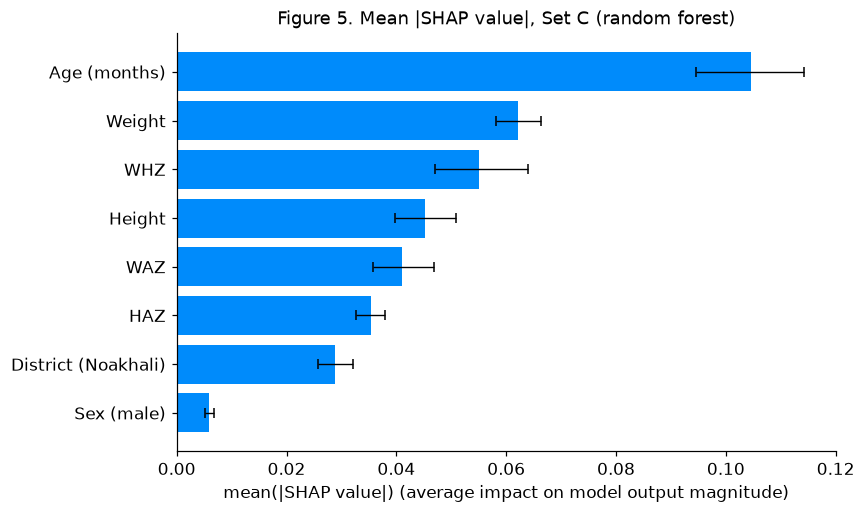

In [ ]:
rf_shap = make_rf_new().fit(Xtr_c, ytr_c)
sv = shap.TreeExplainer(rf_shap).shap_values(Xte_c)
sv1 = sv[1] if isinstance(sv, list) else (sv[..., 1] if np.ndim(sv) == 3 else sv)
Xte_df = pd.DataFrame(Xte_c, columns=labels_full)

A = np.abs(sv1); mean_abs = A.mean(axis=0)
rng = np.random.default_rng(RANDOM_STATE)
boot_shap = np.array([A[rng.integers(0, len(A), len(A))].mean(axis=0) for _ in range(N_BOOT)])
s_lo, s_hi = np.percentile(boot_shap, [2.5, 97.5], axis=0)

print("SHAP mean |value| (Set C random forest), 95% bootstrap interval:")
for i in np.argsort(-mean_abs):
    print(f"  {labels_full[i]:22s} {mean_abs[i]:.4f}  ({s_lo[i]:.4f} to {s_hi[i]:.4f})")

o = np.argsort(mean_abs)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(np.array(labels_full)[o], mean_abs[o], xerr=[mean_abs[o] - s_lo[o], s_hi[o] - mean_abs[o]], capsize=3,
        error_kw=dict(elinewidth=0.9, ecolor='black'), color='#008bfb')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel('mean(|SHAP value|) (average impact on model output magnitude)')
ax.set_title('Figure 5. Mean |SHAP value|, Set C (random forest)', fontsize=12)
plt.tight_layout(); plt.show()

### Figure S1 (Supporting Information). SHAP value distribution, Set C (random forest)

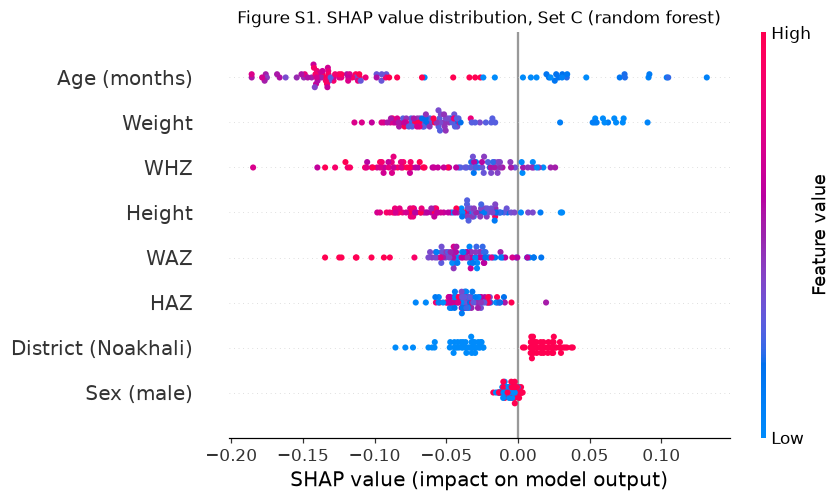

In [ ]:
plt.figure(figsize=(7.5, 4.8))
shap.summary_plot(sv1, Xte_df, show=False)
plt.title('Figure S1. SHAP value distribution, Set C (random forest)', fontsize=11)
plt.tight_layout(); plt.show()

## 9. Table S4 (Supporting Information). Classifier settings


In [ ]:
def core(m):
    return m.named_steps['m'] if isinstance(m, Pipeline) else m

KEYS = {
    'Logistic Regression': ['l1_ratio', 'C', 'solver', 'max_iter', 'class_weight'],
    'Decision Tree': ['max_depth', 'min_samples_leaf', 'criterion', 'class_weight'],
    'SVM (RBF)': ['kernel', 'C', 'gamma', 'probability', 'class_weight'],
    'MLP': ['hidden_layer_sizes', 'activation', 'solver', 'learning_rate_init', 'alpha', 'max_iter', 'early_stopping'],
    'Random Forest': ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features', 'class_weight'],
    'Gradient Boosting': ['n_estimators', 'learning_rate', 'max_depth', 'loss'],
}
rows = []
for mname, keys in KEYS.items():
    p = core(MODELS_NEW[mname]()).get_params()
    rows.append([mname, "; ".join(f"{k}={p[k]}" for k in keys),
                 "Standardized within training folds" if isinstance(MODELS_NEW[mname](), Pipeline) else "Unscaled"])
st = make_stack_new()
rows.append(['Stacking Ensemble',
             f"base learners={[n for n, _ in st.estimators]}; meta-learner=LogisticRegression"
             f"(class_weight={st.final_estimator.class_weight}); cv={st.cv}", "As base learners"])
table_s4 = pd.DataFrame(rows, columns=["Model", "Settings", "Predictor scaling"])
print("Illustration only (Table 4): random forest n_estimators=200, min_samples_leaf=5, no depth limit; "
      "stacking inner random forest n_estimators=150, min_samples_leaf=5.")
table_s4

Illustration only (Table 4): random forest n_estimators=200, min_samples_leaf=5, no depth limit; stacking inner random forest n_estimators=150, min_samples_leaf=5.


,Model,Settings,Predictor scaling
0,Logistic Regression,l1_ratio=0.0; C=1.0; solver=lbfgs; max_iter=2000; class_weight=balanced,Standardized within training folds
1,Decision Tree,max_depth=4; min_samples_leaf=10; criterion=gini; class_weight=balanced,Unscaled
2,SVM (RBF),kernel=rbf; C=1.0; gamma=scale; probability=True; class_weight=balanced,Standardized within training folds
3,MLP,"hidden_layer_sizes=(32,); activation=relu; solver=adam; learning_rate_init=0.001; alpha=1.0; max_iter=3000; early_stopping=False",Standardized within training folds
4,Random Forest,n_estimators=300; max_depth=6; min_samples_leaf=3; max_features=sqrt; class_weight=balanced,Unscaled
5,Gradient Boosting,n_estimators=100; learning_rate=0.1; max_depth=3; loss=log_loss,Unscaled
6,Stacking Ensemble,"base learners=['lr', 'dt', 'rf']; meta-learner=LogisticRegression(class_weight=balanced); cv=5",As base learners


## 10. Table S5 (Supporting Information). Full specification of the recommended model



In [ ]:
def to_raw(pipe):
    s, m = pipe.named_steps['s'], pipe.named_steps['m']
    b = m.coef_[0] / s.scale_
    a = m.intercept_[0] - np.sum(m.coef_[0] * s.mean_ / s.scale_)
    return a, b

a0, b0 = to_raw(lr_pipe)
thr_lr = inner_threshold(make_lr, Xtr_c, ytr_c)

rng = np.random.default_rng(RANDOM_STATE); boot_raw = []
while len(boot_raw) < N_BOOT:
    i = rng.integers(0, len(ytr_c), len(ytr_c))
    if ytr_c[i].sum() < 2:
        continue
    aa, bb = to_raw(make_lr().fit(Xtr_c[i], ytr_c[i])); boot_raw.append(np.r_[aa, bb])
boot_raw = np.array(boot_raw); r_lo, r_hi = np.percentile(boot_raw, [2.5, 97.5], axis=0)

units = ['per month', 'male vs female', 'Noakhali vs Lakshmipur', 'per kg', 'per cm',
         'per Z-score unit', 'per Z-score unit', 'per Z-score unit']
est = np.r_[a0, b0]
rows = [['Intercept', '', f"{est[0]:.4f} ({r_lo[0]:.4f} to {r_hi[0]:.4f})", '', '']]
for j in range(8):
    k = j + 1
    rows.append([labels_full[j], units[j], f"{est[k]:.4f} ({r_lo[k]:.4f} to {r_hi[k]:.4f})",
                 f"{np.exp(est[k]):.3f} ({np.exp(r_lo[k]):.3f} to {np.exp(r_hi[k]):.3f})", f"{coefs[j]:.3f}"])
table_s5 = pd.DataFrame(rows, columns=["Predictor", "Unit", "Coefficient (95% CI)",
                                        "Odds ratio per unit (95% CI)", "Standardized coefficient"])

# check: the written-out equation reproduces the fitted model exactly
p_eq = 1 / (1 + np.exp(-(a0 + Xte_c @ b0)))
print(f"Classification threshold (Youden, inner cross-validation on the training set): {thr_lr:.3f}")
print(f"Max difference between equation and fitted model on test set: {np.abs(p_eq - lr_pipe.predict_proba(Xte_c)[:, 1]).max():.1e}")
print("Coefficients with an interval excluding zero:",
      [labels_full[j] for j in range(8) if r_lo[j+1] > 0 or r_hi[j+1] < 0] or "none")
table_s5

Classification threshold (Youden, inner cross-validation on the training set): 0.662
Max difference between equation and fitted model on test set: 3.3e-16
Coefficients with an interval excluding zero: none


,Predictor,Unit,Coefficient (95% CI),Odds ratio per unit (95% CI),Standardized coefficient
0,Intercept,,5.3149 (-1.8160 to 11.8363),,
1,Age (months),per month,0.0046 (-0.0888 to 0.0761),1.005 (0.915 to 1.079),0.074
2,Sex (male),male vs female,0.4200 (-0.4911 to 1.3535),1.522 (0.612 to 3.871),0.210
3,District (Noakhali),Noakhali vs Lakshmipur,0.7743 (-0.1156 to 1.9932),2.169 (0.891 to 7.339),0.387
4,Weight,per kg,0.0108 (-0.5877 to 0.4606),1.011 (0.556 to 1.585),0.031
5,Height,per cm,-0.0773 (-0.1803 to 0.0361),0.926 (0.835 to 1.037),-0.860
6,WAZ,per Z-score unit,-0.4779 (-0.9201 to 0.0203),0.620 (0.398 to 1.020),-0.962
7,HAZ,per Z-score unit,0.3721 (-0.0820 to 0.7270),1.451 (0.921 to 2.069),1.081
8,WHZ,per Z-score unit,0.1012 (-0.3001 to 0.4657),1.106 (0.741 to 1.593),0.211


In [ ]:
examples = [("Boy, 24 months, Noakhali, 8.5 kg, 78.0 cm", 24, 'M', 1, 8.5, 78.0),
            ("Boy, 30 months, Noakhali, 9.5 kg, 82.0 cm", 30, 'M', 1, 9.5, 82.0)]
for label, age, sex, dist, wt, ht in examples:
    waz = round(float(calc.wfa(Decimal(str(wt)), Decimal(str(age)), sex)), 2)
    haz = round(float(calc.lhfa(Decimal(str(ht)), Decimal(str(age)), sex)), 2)
    whz = round(float((calc.wfl if age < 24 else calc.wfh)(Decimal(str(wt)), Decimal(str(age)), sex, Decimal(str(ht)))), 2)
    x = np.array([age, 1 if sex == 'M' else 0, dist, wt, ht, waz, haz, whz])
    lp = a0 + x @ b0; p = 1 / (1 + np.exp(-lp))
    print(f"{label}: WAZ {waz}, HAZ {haz}, WHZ {whz} -> linear predictor {lp:.3f}, "
          f"predicted value {p:.3f} -> {'malnourished' if p >= thr_lr else 'not malnourished'}")

Boy, 24 months, Noakhali, 8.5 kg, 78.0 cm: WAZ -3.14, HAZ -2.98, WHZ -2.28 -> linear predictor 0.842, predicted value 0.699 -> malnourished
Boy, 30 months, Noakhali, 9.5 kg, 82.0 cm: WAZ -2.88, HAZ -2.92, WHZ -1.8 -> linear predictor 0.518, predicted value 0.627 -> not malnourished


## 11. Table S6 (Supporting Information). Performance by sex and district


In [ ]:
def oof_predictions(cols):
    X = df[cols].values; rows = []
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
    for k, (tr, te) in enumerate(cv.split(X, y_new)):
        m = make_lr().fit(X[tr], y_new[tr])
        thr = inner_threshold(make_lr, X[tr], y_new[tr])
        p = m.predict_proba(X[te])[:, 1]
        rows += [(i, k // 5, pp, int(pp >= thr)) for i, pp in zip(te, p)]
    o = pd.DataFrame(rows, columns=['child', 'rep', 'p', 'pred'])
    o['y'] = y_new[o.child]; o['male'] = df.sex_male.values[o.child]; o['noak'] = df.area_noakhali.values[o.child]
    return o

def grp_metrics(d):
    yy, pr = d.y.values, d.pred.values
    sens = ((pr == 1) & (yy == 1)).sum() / (yy == 1).sum()
    spec = ((pr == 0) & (yy == 0)).sum() / (yy == 0).sum()
    aucv = np.mean([roc_auc_score(g.y, g.p) for _, g in d.groupby('rep')])
    return dict(sens=sens, spec=spec, bacc=(sens + spec) / 2, auc=aucv)

oof = oof_predictions(NEW_SETS['C'])
GROUPS = [('All children', None), ('Girls', ('male', 0)), ('Boys', ('male', 1)),
          ('Lakshmipur', ('noak', 0)), ('Noakhali', ('noak', 1))]
sub = lambda d, g: d if g is None else d[d[g[0]] == g[1]]

point = {name: grp_metrics(sub(oof, g)) for name, g in GROUPS}
by_child = oof.groupby('child').indices
rng = np.random.default_rng(RANDOM_STATE); boots = {name: [] for name, _ in GROUPS}
for _ in range(N_BOOT):
    pick = rng.choice(len(df), len(df), replace=True)
    d = oof.iloc[np.concatenate([by_child[c] for c in pick])]
    for name, g in GROUPS:
        boots[name].append(grp_metrics(sub(d, g)))
boots = {k: pd.DataFrame(v) for k, v in boots.items()}

def ci(name, k, scale=100, nd=1):
    lo, hi = np.percentile(boots[name][k], [2.5, 97.5])
    return f"{point[name][k]*scale:.{nd}f} ({lo*scale:.{nd}f} to {hi*scale:.{nd}f})"

def diff_ci(a, b, k, scale=100, nd=1):
    d = boots[a][k] - boots[b][k]; lo, hi = np.percentile(d, [2.5, 97.5])
    return f"{(point[a][k]-point[b][k])*scale:+.{nd}f} ({lo*scale:.{nd}f} to {hi*scale:.{nd}f})"

rows = []
for name, g in GROUPS:
    kids = sub(oof, g).child.unique()
    rows.append([name, len(kids), int(y_new[kids].sum()), ci(name, 'sens'), ci(name, 'spec'),
                 ci(name, 'bacc'), ci(name, 'auc', 1, 3)])
for a, b in [('Boys', 'Girls'), ('Noakhali', 'Lakshmipur')]:
    rows.append([f"Difference, {a.lower()} - {b.lower()}" if a == 'Boys' else f"Difference, {a} - {b}", '', '',
                 diff_ci(a, b, 'sens'), diff_ci(a, b, 'spec'), diff_ci(a, b, 'bacc'), diff_ci(a, b, 'auc', 1, 3)])
table_s6 = pd.DataFrame(rows, columns=["Group", "n", "Malnourished", "Sensitivity, % (95% CI)",
                                        "Specificity, % (95% CI)", "Balanced accuracy, % (95% CI)", "AUC (95% CI)"])
table_s6

,Group,n,Malnourished,"Sensitivity, % (95% CI)","Specificity, % (95% CI)","Balanced accuracy, % (95% CI)",AUC (95% CI)
0,All children,465,37,54.7 (40.0 to 69.2),76.1 (72.4 to 79.4),65.4 (58.0 to 72.8),0.703 (0.604 to 0.802)
1,Girls,244,18,48.6 (29.2 to 68.8),77.8 (73.1 to 82.5),63.2 (53.0 to 73.9),0.696 (0.556 to 0.828)
2,Boys,221,19,60.5 (39.6 to 81.9),74.1 (68.7 to 79.1),67.3 (56.7 to 78.3),0.713 (0.557 to 0.856)
3,Lakshmipur,223,11,18.2 (2.8 to 39.6),87.0 (83.1 to 90.6),52.6 (44.5 to 63.6),0.562 (0.362 to 0.762)
4,Noakhali,242,26,70.2 (53.9 to 85.8),65.3 (59.4 to 70.6),67.7 (59.4 to 76.0),0.737 (0.624 to 0.846)
5,"Difference, boys - girls",,,+11.9 (-16.2 to 41.2),-3.6 (-10.9 to 3.0),+4.1 (-10.2 to 19.0),+0.017 (-0.186 to 0.226)
6,"Difference, Noakhali - Lakshmipur",,,+52.0 (26.5 to 74.5),-21.8 (-28.3 to -15.4),+15.1 (1.7 to 26.7),+0.175 (-0.048 to 0.397)


**Exploratory refit without district.** Same procedure with district removed from Set C.

In [ ]:
cols_nd = [c for c in NEW_SETS['C'] if c != 'area_noakhali']
oof_nd = oof_predictions(cols_nd)
aucs_nd = []
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
X_nd = df[cols_nd].values
for tr, te in cv.split(X_nd, y_new):
    aucs_nd.append(roc_auc_score(y_new[te], make_lr().fit(X_nd[tr], y_new[tr]).predict_proba(X_nd[te])[:, 1]))
print(f"Cross-validated AUC without district (mean over 20 folds): {np.mean(aucs_nd):.3f}")
for name, g in [('Lakshmipur', ('noak', 0)), ('Noakhali', ('noak', 1))]:
    m = grp_metrics(sub(oof_nd, g))
    print(f"  {name}: sensitivity {m['sens']*100:.1f}%, specificity {m['spec']*100:.1f}%")

Cross-validated AUC without district (mean over 20 folds): 0.705
  Lakshmipur: sensitivity 40.9%, specificity 71.9%
  Noakhali: sensitivity 63.5%, specificity 71.8%


## 11b. Table S7 (Supporting Information). Comparison of all classifiers using all 37 malnourished children

In [ ]:
def oof_model(proto, cols):
    X = df[cols].values; P = np.zeros((4, len(df))); D = np.zeros((4, len(df)), dtype=int)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
    for k, (tr, te) in enumerate(cv.split(X, y_new)):
        m = clone(proto()).fit(X[tr], y_new[tr])
        thr = inner_threshold(proto, X[tr], y_new[tr])
        p = m.predict_proba(X[te])[:, 1]
        P[k // 5, te] = p; D[k // 5, te] = (p >= thr).astype(int)
    return P, D

POOL = {m: oof_model(p, NEW_SETS['C']) for m, p in MODELS_NEW.items()}
pos = y_new == 1; neg = ~pos

def pooled(m, w):
    P, D = POOL[m]
    tp = (D[:, pos] * w[pos]).sum(); fn = ((1 - D[:, pos]) * w[pos]).sum()
    tn = ((1 - D[:, neg]) * w[neg]).sum(); fp = (D[:, neg] * w[neg]).sum()
    se, sp = tp / (tp + fn), tn / (tn + fp)
    au = np.mean([roc_auc_score(y_new, P[r], sample_weight=w) for r in range(4)])
    return np.array([se, sp, (se + sp) / 2, au, (D[:, pos] * w[pos]).sum() / 4])

w1 = np.ones(len(df)); point7 = {m: pooled(m, w1) for m in MODEL_ORDER}
rng = np.random.default_rng(RANDOM_STATE); boot7 = {m: [] for m in MODEL_ORDER}
for _ in range(N_BOOT):
    w = np.bincount(rng.integers(0, len(df), len(df)), minlength=len(df)).astype(float)
    for m in MODEL_ORDER:
        boot7[m].append(pooled(m, w))
boot7 = {m: np.array(v) for m, v in boot7.items()}

def f7(v, lo, hi, j):
    return f"{v[j]:.3f} ({lo[j]:.3f} to {hi[j]:.3f})" if j == 3 else f"{v[j]*100:.1f} ({lo[j]*100:.1f} to {hi[j]*100:.1f})"

rows = []
for m in MODEL_ORDER:
    lo, hi = np.percentile(boot7[m], [2.5, 97.5], axis=0)
    rows.append([m, f"{point7[m][4]:.1f}"] + [f7(point7[m], lo, hi, j) for j in range(4)])
for m in MODEL_ORDER[1:]:
    d = boot7['Logistic Regression'] - boot7[m]; dp = point7['Logistic Regression'] - point7[m]
    lo, hi = np.percentile(d, [2.5, 97.5], axis=0)
    rows.append([f"Difference, logistic regression - {m}", ""] +
                [(f"{dp[j]:+.3f} ({lo[j]:.3f} to {hi[j]:.3f})" if j == 3 else
                  f"{dp[j]*100:+.1f} ({lo[j]*100:.1f} to {hi[j]*100:.1f})") for j in range(4)])
table_s7 = pd.DataFrame(rows, columns=["Model", "Detected (of 37, mean per repeat)", "Sensitivity, % (95% CI)",
                                        "Specificity, % (95% CI)", "Balanced accuracy, % (95% CI)", "AUC (95% CI)"])
table_s7

,Model,"Detected (of 37, mean per repeat)","Sensitivity, % (95% CI)","Specificity, % (95% CI)","Balanced accuracy, % (95% CI)",AUC (95% CI)
0,Logistic Regression,20.2,54.7 (40.0 to 69.2),76.1 (72.4 to 79.4),65.4 (58.0 to 72.8),0.703 (0.604 to 0.802)
1,Decision Tree,15.5,41.9 (30.9 to 54.1),77.2 (74.5 to 79.8),59.5 (54.0 to 65.8),0.605 (0.517 to 0.698)
2,SVM (RBF),14.8,39.9 (29.1 to 51.8),75.6 (72.6 to 78.7),57.8 (52.3 to 64.0),0.615 (0.510 to 0.724)
3,MLP,18.0,48.6 (35.9 to 62.9),71.8 (68.2 to 75.3),60.2 (53.5 to 67.6),0.657 (0.548 to 0.769)
4,Random Forest,18.8,50.7 (36.8 to 64.7),75.9 (72.4 to 79.4),63.3 (56.3 to 70.5),0.642 (0.535 to 0.750)
5,Gradient Boosting,18.0,48.6 (35.5 to 62.8),65.9 (62.5 to 69.1),57.3 (50.6 to 64.3),0.591 (0.496 to 0.688)
6,Stacking Ensemble,19.8,53.4 (39.8 to 68.0),75.6 (72.1 to 79.0),64.5 (57.4 to 72.1),0.668 (0.562 to 0.770)
7,"Difference, logistic regression - Decision Tree",,+12.8 (2.1 to 24.2),-1.1 (-4.1 to 1.9),+5.9 (0.3 to 11.5),+0.098 (0.026 to 0.176)
8,"Difference, logistic regression - SVM (RBF)",,+14.9 (6.0 to 24.2),+0.4 (-2.5 to 3.2),+7.6 (3.1 to 12.5),+0.088 (0.043 to 0.140)
9,"Difference, logistic regression - MLP",,+6.1 (-2.7 to 15.6),+4.2 (1.9 to 6.4),+5.1 (0.6 to 9.8),+0.046 (0.007 to 0.087)


**Sensitivity analysis: thresholds chosen on training-data predictions

In [ ]:
def oof_train_thr(proto, cols):
    X = df[cols].values; D = np.zeros((4, len(df)), dtype=int)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
    for k, (tr, te) in enumerate(cv.split(X, y_new)):
        m = clone(proto()).fit(X[tr], y_new[tr])
        thr = youden_threshold(y_new[tr], m.predict_proba(X[tr])[:, 1])
        D[k // 5, te] = (m.predict_proba(X[te])[:, 1] >= thr).astype(int)
    return D

rows = []
for mname, proto in MODELS_NEW.items():
    D_tr = oof_train_thr(proto, NEW_SETS['C']); D_in = POOL[mname][1]
    s_tr = D_tr[:, pos].mean(); sp_tr = 1 - D_tr[:, neg].mean()
    s_in = D_in[:, pos].mean(); sp_in = 1 - D_in[:, neg].mean()
    rows.append([mname, f"{s_tr*100:.1f}", f"{sp_tr*100:.1f}", f"{s_in*100:.1f}", f"{sp_in*100:.1f}"])
pd.DataFrame(rows, columns=["Model", "Sensitivity, training-data threshold", "Specificity, training-data threshold",
                            "Sensitivity, inner-CV threshold", "Specificity, inner-CV threshold"])

,Model,"Sensitivity, training-data threshold","Specificity, training-data threshold","Sensitivity, inner-CV threshold","Specificity, inner-CV threshold"
0,Logistic Regression,57.4,75.5,54.7,76.1
1,Decision Tree,50.0,71.0,41.9,77.2
2,SVM (RBF),46.6,79.6,39.9,75.6
3,MLP,52.0,76.2,48.6,71.8
4,Random Forest,29.7,92.9,50.7,75.9
5,Gradient Boosting,7.4,95.4,48.6,65.9
6,Stacking Ensemble,52.0,79.4,53.4,75.6


### Optimism-corrected AUC of the recommended model

In [ ]:
X_all = df[NEW_SETS['C']].values
full_lr = make_lr().fit(X_all, y_new)
apparent = roc_auc_score(y_new, full_lr.decision_function(X_all))
rng = np.random.default_rng(RANDOM_STATE); opt = []
while len(opt) < 500:
    i = rng.integers(0, len(df), len(df))
    if y_new[i].sum() < 2:
        continue
    mb = make_lr().fit(X_all[i], y_new[i])
    opt.append(roc_auc_score(y_new[i], mb.decision_function(X_all[i])) - roc_auc_score(y_new, mb.decision_function(X_all)))
print(f"Apparent AUC {apparent:.3f}; mean optimism {np.mean(opt):.3f}; optimism-corrected AUC {apparent - np.mean(opt):.3f}")

Apparent AUC 0.756; mean optimism 0.045; optimism-corrected AUC 0.710


## 12. Analyses added in response to the reviewers


### 12a. Table 6 with 95% percentile intervals for every metric


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2

def pi_pct(b, k):
    return f"{b[k]*100:.1f} ({b[k + '_lo']*100:.1f} to {b[k + '_hi']*100:.1f})"

rows = []
for sname in ['A', 'B', 'C']:
    b = best_row(new_grid, sname, by='auc')
    rows.append([label_map6[sname], b['model'], pi_pct(b, 'acc'), pi_pct(b, 'bacc'), pi_pct(b, 'sens'),
                 pi_pct(b, 'spec'), f"{b.auc:.3f} ({b.auc_lo:.3f} to {b.auc_hi:.3f})"])
pd.DataFrame(rows, columns=["Predictor set", "Best model", "Accuracy, % (95% PI)", "Balanced accuracy, % (95% PI)",
                            "Sensitivity, % (95% PI)", "Specificity, % (95% PI)", "AUC (95% PI)"])

,Predictor set,Best model,"Accuracy, % (95% PI)","Balanced accuracy, % (95% PI)","Sensitivity, % (95% PI)","Specificity, % (95% PI)",AUC (95% PI)
0,A: demographics,Logistic Regression,71.7 (58.6 to 86.2),65.7 (54.9 to 77.1),58.6 (25.3 to 86.7),72.8 (56.7 to 90.4),0.701 (0.579 to 0.801)
1,"B: + weight, height",Logistic Regression,75.6 (58.0 to 90.9),65.6 (55.0 to 74.9),53.8 (14.3 to 80.6),77.4 (57.3 to 97.2),0.711 (0.595 to 0.814)
2,C: + WAZ/HAZ/WHZ (recommended),Logistic Regression,74.4 (57.0 to 88.7),65.2 (54.6 to 77.9),54.5 (21.1 to 75.0),76.0 (56.1 to 93.0),0.706 (0.583 to 0.811)


### 12b. Held-out test set: exact (Clopper-Pearson) 95% confidence intervals

Logistic regression, Set C, held-out test set (n = 93, 7 malnourished children).

In [ ]:
def cp_ci(k, n, alpha=0.05):
    lo = 0.0 if k == 0 else stats.beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else stats.beta.ppf(1 - alpha / 2, k + 1, n - k)
    return lo, hi

f = fitted[('C', 'Logistic Regression')]
tn, fp, fn, tp = confusion_matrix(f['yte'], f['pred'], labels=[0, 1]).ravel()
rows = []
for name, k, n in [("Accuracy", tp + tn, tp + tn + fp + fn), ("Sensitivity", tp, tp + fn),
                   ("Specificity", tn, tn + fp), ("Positive predictive value", tp, tp + fp),
                   ("Negative predictive value", tn, tn + fn)]:
    lo, hi = cp_ci(k, n)
    rows.append([name, f"{k}/{n}", f"{k/n*100:.1f}", f"{lo*100:.1f} to {hi*100:.1f}"])
print(f"Confusion matrix: TN {tn}, FP {fp}, FN {fn}, TP {tp}; "
      f"balanced accuracy {balanced_accuracy_score(f['yte'], f['pred'])*100:.1f}%; AUC {roc_auc_score(f['yte'], f['pr']):.3f}")
pd.DataFrame(rows, columns=["Metric", "n/N", "%", "Exact 95% CI"])

Confusion matrix: TN 78, FP 8, FN 4, TP 3; balanced accuracy 66.8%; AUC 0.723


,Metric,n/N,%,Exact 95% CI
0,Accuracy,81/93,87.1,78.5 to 93.2
1,Sensitivity,3/7,42.9,9.9 to 81.6
2,Specificity,78/86,90.7,82.5 to 95.9
3,Positive predictive value,3/11,27.3,6.0 to 61.0
4,Negative predictive value,78/82,95.1,88.0 to 98.7


### 12c. Table S8 (Supporting Information). Correlations and variance inflation factors


In [ ]:
cont = ['MONTH', 'WEIGHT', 'HEIGHT', 'WAZ', 'HAZ', 'WHZ']
corr_lab = {'MONTH': 'Age', 'WEIGHT': 'Weight', 'HEIGHT': 'Height', 'WAZ': 'WAZ', 'HAZ': 'HAZ', 'WHZ': 'WHZ', 'MUAC': 'MUAC'}
corr = df[cont + ['MUAC']].corr().round(2).rename(index=corr_lab, columns=corr_lab)
print("Pearson correlations (n = 465):")
display(corr)

def vif_table(cols):
    Xv = sm.add_constant(df[cols].astype(float)).values
    return {c: variance_inflation_factor(Xv, i + 1) for i, c in enumerate(cols)}

vif_c, vif_b = vif_table(NEW_SETS['C']), vif_table(NEW_SETS['B'])
sign_same = (np.sign(boot_std) == np.sign(coefs)).mean(axis=0) * 100
rows = []
for i, c in enumerate(NEW_SETS['C']):
    rows.append([labels_full[i], f"{vif_b[c]:.1f}" if c in vif_b else "", f"{vif_c[c]:.1f}",
                 f"{coefs[i]:+.2f}", f"{sign_same[i]:.0f}"])
table_s8 = pd.DataFrame(rows, columns=["Predictor", "VIF, Set B", "VIF, Set C", "Standardized coefficient (Set C)",
                                        "Bootstrap resamples with the same sign, %"])
table_s8

Pearson correlations (n = 465):


,Age,Weight,Height,WAZ,HAZ,WHZ,MUAC
Age,1.00,0.53,0.63,-0.36,-0.38,-0.05,0.30
Weight,0.53,1.00,0.75,0.57,0.29,0.48,0.39
Height,0.63,0.75,1.00,0.21,0.44,-0.20,0.35
WAZ,-0.36,0.57,0.21,1.00,0.72,0.61,0.15
HAZ,-0.38,0.29,0.44,0.72,1.00,-0.11,0.07
WHZ,-0.05,0.48,-0.20,0.61,-0.11,1.00,0.13
MUAC,0.30,0.39,0.35,0.15,0.07,0.13,1.00


,Predictor,"VIF, Set B","VIF, Set C",Standardized coefficient (Set C),"Bootstrap resamples with the same sign, %"
0,Age (months),1.7,27.2,+0.07,54
1,Sex (male),1.0,1.1,+0.21,82
2,District (Noakhali),1.0,1.0,+0.39,96
3,Weight,2.3,41.8,+0.03,50
4,Height,2.7,63.0,-0.86,91
5,WAZ,,150.1,-0.96,97
6,HAZ,,58.1,+1.08,95
7,WHZ,,93.8,+0.21,68


### 12d. Incremental value of each predictor set


In [ ]:
def oof_prob(make_model, X, y):
    P = np.zeros((4, len(y)))
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
    for k, (tr, te) in enumerate(cv.split(X, y)):
        P[k // 5, te] = make_model().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return P

def pooled_auc(P, y, w=None):
    return np.mean([roc_auc_score(y, P[r], sample_weight=w) for r in range(P.shape[0])])

P_set = {s: oof_prob(make_lr, df[c].values, y_new) for s, c in NEW_SETS.items()}
pt_set = {s: pooled_auc(P_set[s], y_new) for s in P_set}
rng = np.random.default_rng(RANDOM_STATE); bs_set = {s: [] for s in P_set}
for _ in range(N_BOOT):
    w = np.bincount(rng.integers(0, len(df), len(df)), minlength=len(df)).astype(float)
    for s in P_set:
        bs_set[s].append(pooled_auc(P_set[s], y_new, w))
bs_set = {s: np.array(v) for s, v in bs_set.items()}

llf = {s: sm.Logit(y_new, sm.add_constant(df[c].astype(float))).fit(disp=0).llf for s, c in NEW_SETS.items()}
rows = []
for s in ['A', 'B', 'C']:
    lo, hi = np.percentile(bs_set[s], [2.5, 97.5])
    rows.append([f"Set {s}", f"{pt_set[s]:.3f} ({lo:.3f} to {hi:.3f})", ""])
for a, b, dof in [('B', 'A', 2), ('C', 'B', 3)]:
    d = bs_set[a] - bs_set[b]; lo, hi = np.percentile(d, [2.5, 97.5])
    lr_stat = 2 * (llf[a] - llf[b])
    rows.append([f"Difference, Set {a} - Set {b}", f"{pt_set[a] - pt_set[b]:+.3f} ({lo:.3f} to {hi:.3f})",
                 f"chi-square {lr_stat:.2f}, df {dof}, P = {fmt_p(chi2.sf(lr_stat, dof))}"])
pd.DataFrame(rows, columns=["", "Pooled out-of-fold AUC (95% CI)", "Likelihood-ratio test"])

,,Pooled out-of-fold AUC (95% CI),Likelihood-ratio test
0,Set A,0.698 (0.601 to 0.800),
1,Set B,0.706 (0.602 to 0.808),
2,Set C,0.703 (0.604 to 0.802),
3,"Difference, Set B - Set A",+0.008 (-0.044 to 0.060),"chi-square 7.26, df 2, P = .03"
4,"Difference, Set C - Set B",-0.003 (-0.020 to 0.014),"chi-square 3.08, df 3, P = .38"


### 12e. Table S9 (Supporting Information). Sensitivity of the primary model to penalty strength


In [ ]:
def cal_slope(lin, y):
    return sm.Logit(y, sm.add_constant(lin)).fit(disp=0).params[1]

X_all = df[NEW_SETS['C']].values
cv20 = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
rows = []; pen_coef = {}
for C_val, C_lab in [(0.01, "0.01"), (0.1, "0.1"), (1.0, "1 (main analysis)"), (10.0, "10"), (1e6, "No penalty")]:
    mk = lambda: Pipeline([('s', StandardScaler()),
                           ('m', LogisticRegression(C=C_val, max_iter=5000, class_weight='balanced', random_state=RANDOM_STATE))])
    fold_auc = [roc_auc_score(y_new[te], mk().fit(X_all[tr], y_new[tr]).predict_proba(X_all[te])[:, 1])
                for tr, te in cv20.split(X_all, y_new)]
    full = mk().fit(X_all, y_new); lin = full.decision_function(X_all)
    app_auc, app_slope = roc_auc_score(y_new, lin), cal_slope(lin, y_new)
    pen_coef[C_lab] = full.named_steps['m'].coef_[0]
    rng = np.random.default_rng(RANDOM_STATE); o_auc, o_slope = [], []
    while len(o_auc) < 500:
        i = rng.integers(0, len(df), len(df))
        if y_new[i].sum() < 2:
            continue
        mb = mk().fit(X_all[i], y_new[i]); lb, lo_ = mb.decision_function(X_all[i]), mb.decision_function(X_all)
        o_auc.append(roc_auc_score(y_new[i], lb) - roc_auc_score(y_new, lo_))
        o_slope.append(cal_slope(lb, y_new[i]) - cal_slope(lo_, y_new))
    rows.append([C_lab, f"{np.mean(fold_auc):.3f} ({np.percentile(fold_auc, 2.5):.3f} to {np.percentile(fold_auc, 97.5):.3f})",
                 f"{app_auc:.3f}", f"{np.mean(o_auc):.3f}", f"{app_auc - np.mean(o_auc):.3f}",
                 f"{app_slope - np.mean(o_slope):.2f}"])
table_s9 = pd.DataFrame(rows, columns=["Penalty (C)", "Cross-validated AUC (95% PI)", "Apparent AUC", "Optimism",
                                        "Corrected AUC", "Corrected calibration slope"])
iw = NEW_SETS['C'].index('WAZ')
print("Standardized WAZ coefficient by penalty:", {k: round(float(v[iw]), 2) for k, v in pen_coef.items()})
table_s9

Standardized WAZ coefficient by penalty: {'0.01': -0.06, '0.1': -0.21, '1 (main analysis)': -1.27, '10': -3.61, 'No penalty': -4.71}


,Penalty (C),Cross-validated AUC (95% PI),Apparent AUC,Optimism,Corrected AUC,Corrected calibration slope
0,0.01,0.718 (0.602 to 0.823),0.743,0.029,0.713,1.46
1,0.1,0.714 (0.600 to 0.816),0.747,0.037,0.710,1.04
2,1 (main analysis),0.706 (0.583 to 0.811),0.756,0.045,0.710,0.92
3,10,0.704 (0.567 to 0.828),0.766,0.051,0.715,0.80
4,No penalty,0.702 (0.560 to 0.831),0.769,0.053,0.715,0.75


### 12f. Calibration of the primary model and Figure S5


In [ ]:
def make_lr_unweighted():
    return Pipeline([('s', StandardScaler()), ('m', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

P_cal = {k: np.zeros((4, len(df))) for k in ['As fitted (balanced weights)', 'After prior correction', 'Unweighted model']}
for k, (tr, te) in enumerate(cv20.split(X_all, y_new)):
    pw = make_lr().fit(X_all[tr], y_new[tr]).predict_proba(X_all[te])[:, 1]
    n1 = y_new[tr].sum(); n0 = len(tr) - n1; odds = pw / (1 - pw) * (n1 / n0)
    P_cal['As fitted (balanced weights)'][k // 5, te] = pw
    P_cal['After prior correction'][k // 5, te] = odds / (1 + odds)
    P_cal['Unweighted model'][k // 5, te] = make_lr_unweighted().fit(X_all[tr], y_new[tr]).predict_proba(X_all[te])[:, 1]

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def cal_stats(P, w):
    out = []
    for r in range(4):
        p = P[r]; l = logit(p)
        slope = sm.GLM(y_new, sm.add_constant(l), family=sm.families.Binomial(), freq_weights=w).fit().params[1]
        citl = sm.GLM(y_new, np.ones((len(y_new), 1)), family=sm.families.Binomial(), offset=l, freq_weights=w).fit().params[0]
        out.append([np.average(p, weights=w), np.average((p - y_new) ** 2, weights=w), citl, slope,
                    roc_auc_score(y_new, p, sample_weight=w)])
    return np.mean(out, axis=0)

rng = np.random.default_rng(RANDOM_STATE)
W_cal = [np.bincount(rng.integers(0, len(df), len(df)), minlength=len(df)).astype(float) for _ in range(1000)]
rows = []
for name, P in P_cal.items():
    pt = cal_stats(P, np.ones(len(df))); bs = np.array([cal_stats(P, w) for w in W_cal])
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    rows.append([name, f"{pt[0]:.3f}", f"{pt[1]:.3f} ({lo[1]:.3f} to {hi[1]:.3f})", f"{pt[2]:.2f} ({lo[2]:.2f} to {hi[2]:.2f})",
                 f"{pt[3]:.2f} ({lo[3]:.2f} to {hi[3]:.2f})", f"{pt[4]:.3f}"])
print(f"Observed prevalence {y_new.mean():.3f}; Brier score when predicting the prevalence for every child "
      f"{y_new.mean() * (1 - y_new.mean()):.3f}")
pd.DataFrame(rows, columns=["Probabilities", "Mean predicted probability", "Brier score (95% CI)",
                            "Calibration-in-the-large (95% CI)", "Calibration slope (95% CI)", "AUC"])

Observed prevalence 0.080; Brier score when predicting the prevalence for every child 0.073


,Probabilities,Mean predicted probability,Brier score (95% CI),Calibration-in-the-large (95% CI),Calibration slope (95% CI),AUC
0,As fitted (balanced weights),0.418,0.203 (0.188 to 0.220),-2.41 (-2.79 to -2.10),0.83 (0.39 to 1.36),0.703
1,After prior correction,0.077,0.068 (0.050 to 0.087),0.04 (-0.34 to 0.35),0.83 (0.38 to 1.36),0.703
2,Unweighted model,0.079,0.068 (0.050 to 0.086),0.00 (-0.38 to 0.32),0.84 (0.44 to 1.34),0.715


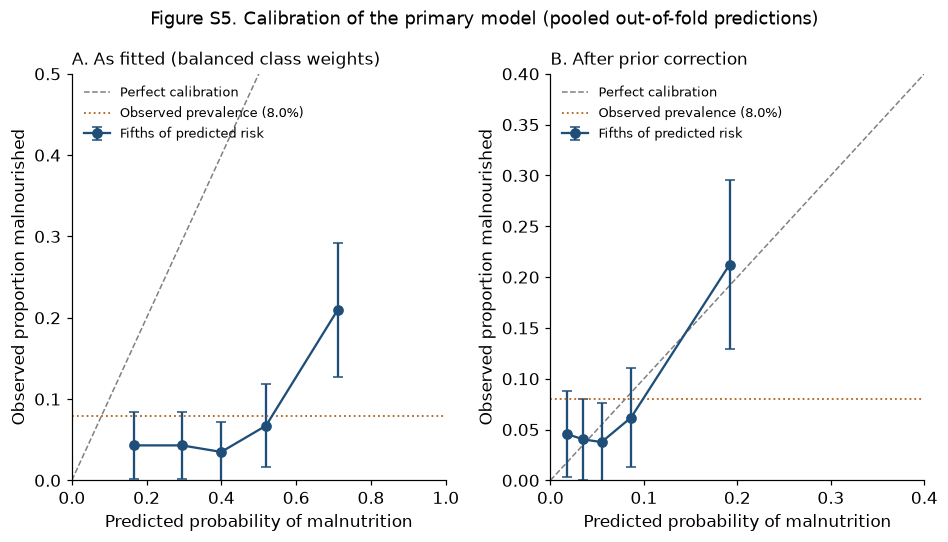

In [ ]:
yy = np.tile(y_new, 4)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), gridspec_kw={'wspace': 0.28})
for ax, (name, ttl, lim) in zip(axes, [('As fitted (balanced weights)', 'A. As fitted (balanced class weights)', 1.0),
                                       ('After prior correction', 'B. After prior correction', 0.4)]):
    p = P_cal[name].ravel()
    g = pd.DataFrame({'p': p, 'y': yy, 'q': pd.qcut(p, 5, labels=False)}).groupby('q').agg(
        pred=('p', 'mean'), obs=('y', 'mean'), n=('y', 'size'))
    se = np.sqrt(g.obs * (1 - g.obs) / (g.n / 4))
    ax.plot([0, lim], [0, lim], ls='--', c='0.5', lw=1, label='Perfect calibration')
    ax.errorbar(g.pred, g.obs, yerr=1.96 * se, fmt='o-', c='#1f4e79', ms=6, lw=1.5, capsize=3, label='Fifths of predicted risk')
    ax.axhline(y_new.mean(), c='#b5651d', ls=':', lw=1.2, label='Observed prevalence (8.0%)')
    ax.set_xlim(0, lim); ax.set_ylim(0, 0.5 if lim == 1.0 else lim); ax.set_title(ttl, fontsize=11, loc='left')
    ax.set_xlabel('Predicted probability of malnutrition'); ax.set_ylabel('Observed proportion malnourished')
    ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False, fontsize=8.5, loc='upper left')
fig.suptitle('Figure S5. Calibration of the primary model (pooled out-of-fold predictions)', fontsize=12, y=1.0)
plt.show()

### 12g. Table S10 (Supporting Information). McNemar discordant pairs by outcome class

In [ ]:
rows = []
for mname in MODEL_ORDER:
    if mname == 'Logistic Regression':
        continue
    other = fitted[('C', mname)]['pred']; row = [f"Logistic regression vs {mname}"]
    for cls in (1, 0):
        k = yte_c == cls; lr_ok = lr_pred[k] == yte_c[k]; ot_ok = other[k] == yte_c[k]
        b, c = int((~lr_ok & ot_ok).sum()), int((lr_ok & ~ot_ok).sum())
        p = mcnemar([[0, b], [c, 0]], exact=True).pvalue if (b + c) else 1.0
        q = Decimal(str(float(p))).quantize(Decimal('0.001') if p < 0.01 else Decimal('0.01'), rounding='ROUND_HALF_UP')
        row += [f"{b} / {c}", fmt_p(p) if p < 0.001 else fmt_p(float(q))]
    rows.append(row)
table_s10 = pd.DataFrame(rows, columns=["Comparison", "Malnourished (n = 7): comparator only / LR only", "P",
                                         "Normal (n = 86): comparator only / LR only", "P "])
table_s10

,Comparison,Malnourished (n = 7): comparator only / LR only,P,Normal (n = 86): comparator only / LR only,P
0,Logistic regression vs Decision Tree,1 / 3,.63,5 / 5,>.99
1,Logistic regression vs SVM (RBF),1 / 1,>.99,0 / 12,<.001
2,Logistic regression vs MLP,1 / 2,>.99,0 / 8,.008
3,Logistic regression vs Random Forest,1 / 3,.63,0 / 6,.03
4,Logistic regression vs Gradient Boosting,1 / 3,.63,6 / 6,>.99
5,Logistic regression vs Stacking Ensemble,0 / 1,>.99,0 / 11,<.001


### 12h. Sensitivity analyses and recording checks

In [ ]:
def auc_with_ci(d):
    X = d[NEW_SETS['C']].values; y = d.muac_malnourished.values
    P = oof_prob(make_lr, X, y); pt = pooled_auc(P, y)
    rng = np.random.default_rng(RANDOM_STATE)
    bs = [pooled_auc(P, y, np.bincount(rng.integers(0, len(y), len(y)), minlength=len(y)).astype(float)) for _ in range(N_BOOT)]
    return len(y), int(y.sum()), f"{pt:.3f} ({np.percentile(bs, 2.5):.3f} to {np.percentile(bs, 97.5):.3f})"

rz = {k: np.array(v) for k, v in recomputed.items()}
flag = ((rz['WAZ'] < -6) | (rz['WAZ'] > 5) | (rz['HAZ'] < -6) | (rz['HAZ'] > 6) | (rz['WHZ'] < -5) | (rz['WHZ'] > 5))
flag_supplied = ((df.WAZ < -6) | (df.WAZ > 5) | (df.HAZ < -6) | (df.HAZ > 6) | (df.WHZ < -5) | (df.WHZ > 5)).values
print(f"WHO flags in the analysis dataset. Recomputed Z-scores: {int(flag.sum())} records "
      f"(WAZ {int(((rz['WAZ'] < -6) | (rz['WAZ'] > 5)).sum())}, HAZ {int(((rz['HAZ'] < -6) | (rz['HAZ'] > 6)).sum())}, "
      f"WHZ {int(((rz['WHZ'] < -5) | (rz['WHZ'] > 5)).sum())}). Supplied Z-scores: {int(flag_supplied.sum())} records.")

young = ((df.MONTH >= 18) & (df.MONTH < 24)).values
d_adj = df.copy(); new_haz, new_whz = [], []
for (_, r), is_young in zip(df.iterrows(), young):
    if not is_young:
        new_haz.append(np.nan); new_whz.append(np.nan); continue
    sex = 'M' if r.SEX == 'male' else 'F'
    age, w, h = Decimal(str(r.MONTH)), Decimal(str(r.WEIGHT)), Decimal(str(round(r.HEIGHT + 0.7, 1)))
    new_haz.append(z_or_nan(calc.lhfa, h, age, sex)); new_whz.append(z_or_nan(calc.wfl, w, age, sex, h))
d_haz = np.where(young, np.array(new_haz) - rz['HAZ'], 0.0); d_whz = np.where(young, np.array(new_whz) - rz['WHZ'], 0.0)
d_adj['HEIGHT'] = df.HEIGHT + 0.7 * young; d_adj['HAZ'] = df.HAZ + d_haz; d_adj['WHZ'] = df.WHZ + d_whz
print(f"Children aged 18 to 24 months: {int(young.sum())}; mean change in HAZ {d_haz[young].mean():+.2f}, "
      f"in WHZ {d_whz[young].mean():+.2f}; reclassified from stunted to not stunted: "
      f"{int(((df.HAZ < -2) & (d_adj.HAZ >= -2)).sum())}")

corrected = (df.BOD_raw != df.BOD_fixed).values
rows = [["Full sample"] + list(auc_with_ci(df)),
        ["Excluding records flagged on recomputation"] + list(auc_with_ci(df[~flag])),
        ["Heights of children aged 18 to 24 months increased by 0.7 cm"] + list(auc_with_ci(d_adj)),
        ["Excluding children with a corrected birth year"] + list(auc_with_ci(df[~corrected]))]
pd.DataFrame(rows, columns=["Analysis", "Children", "Malnourished", "Pooled out-of-fold AUC (95% CI)"])

WHO flags in the analysis dataset. Recomputed Z-scores: 10 records (WAZ 1, HAZ 2, WHZ 7). Supplied Z-scores: 0 records.
Children aged 18 to 24 months: 41; mean change in HAZ +0.24, in WHZ -0.12; reclassified from stunted to not stunted: 1


,Analysis,Children,Malnourished,Pooled out-of-fold AUC (95% CI)
0,Full sample,465,37,0.703 (0.604 to 0.802)
1,Excluding records flagged on recomputation,455,35,0.666 (0.554 to 0.776)
2,Heights of children aged 18 to 24 months increased by 0.7 cm,465,37,0.704 (0.605 to 0.803)
3,Excluding children with a corrected birth year,440,36,0.663 (0.553 to 0.769)


In [ ]:
print("Recording of measurements and age (Section 2.2):")
print(f"  Weights recorded as whole kilograms: {(df.WEIGHT % 1 == 0).mean()*100:.1f}%; "
      f"as a multiple of 0.5 kg: {((df.WEIGHT * 2) % 1 == 0).mean()*100:.1f}%")
print(f"  Heights recorded as whole centimetres: {(df.HEIGHT % 1 == 0).mean()*100:.1f}%")
print(f"  Age range: {df.MONTH.min():.2f} to {df.MONTH.max():.2f} months")
print(f"  Two-digit birth years corrected: {int(corrected.sum())} "
      f"(raw values {int(df.BOD_raw[corrected].min())} to {int(df.BOD_raw[corrected].max())})")
age_by_year = df.groupby('BOD_fixed').MONTH.agg(['min', 'max', 'count']).round(1)
age_by_year.columns = ['Youngest (months)', 'Oldest (months)', 'Children']; age_by_year.index.name = 'Birth year'
age_by_year

Recording of measurements and age (Section 2.2):
  Weights recorded as whole kilograms: 95.3%; as a multiple of 0.5 kg: 99.8%
  Heights recorded as whole centimetres: 95.5%
  Age range: 6.47 to 59.96 months
  Two-digit birth years corrected: 25 (raw values 18 to 23)


,Youngest (months),Oldest (months),Children
Birth year,,,
2018,57.8,60.0,18
2019,45.7,57.4,120
2020,34.0,45.3,92
2021,21.5,33.4,93
2022,9.7,21.2,100
2023,6.5,9.4,42


## 13. Package versions

In [ ]:
import sys, sklearn, scipy, statsmodels, matplotlib
from importlib.metadata import version
print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy       :", scipy.__version__)
print("statsmodels :", statsmodels.__version__)
print("shap        :", shap.__version__)
print("pygrowup    :", version('pygrowup'))
print("matplotlib  :", matplotlib.__version__)

Python      : 3.12.3
numpy       : 2.4.4
pandas      : 3.0.2
scikit-learn: 1.8.0
scipy       : 1.17.1
statsmodels : 0.14.6
shap        : 0.52.0
pygrowup    : 0.8.2
matplotlib  : 3.11.2
